# Agents, Session 6B: Meet CrewAI

## From writing the teamwork to describing it

In Session 6A, each agent took one `create_agent(...)` call. But making them work *together* took much more code, all written by hand: wrapper functions so the boss could call the experts, a loop to pass messages along, a router, a step to combine the answers.

**CrewAI** is a framework for teams of agents. Instead of writing the teamwork, you *describe* it: who is on the team, what jobs need doing, and in what order. CrewAI runs the rest.

We'll meet it one small step at a time, starting from something you already know: a single agent.

| Step | You'll learn |
|---|---|
| 1 | The same agent you know, written in CrewAI |
| 2 | Giving it a tool |
| 3 | Tasks: separating *what to do* from *who does it* |
| 4 | Two agents in a row (a pipeline) |
| 5 | A manager who decides who does what |
| 6 | Agents asking each other for help |

### Setup

This notebook works in **Google Colab** and in **VS Code**, with your key in Colab Secrets or in a `.env` file, exactly as in Session 6A.

Installing CrewAI takes a minute or two. The `[google-genai]` part installs CrewAI's connection to Gemini; without it, CrewAI can't talk to Gemini models.

*In Colab: if a "Restart session" message appears after the install, click it, then carry on from the next cell (no need to install again).*

In [ ]:
%pip install -q "crewai[google-genai]>=1.15" requests python-dotenv

Two lines in the next cell are worth knowing about:

- `CREWAI_TRACING_ENABLED = "false"`: the first time CrewAI runs on a computer, it asks a yes/no question about sending usage traces. In a notebook, that question would wait forever for an answer. This line answers "no" in advance.
- `LLM(model="gemini/...")`: CrewAI's way of saying which model the agents use. It's the same Gemini model as always; the `gemini/` part tells CrewAI which company makes it.

In [ ]:
import os
os.environ["CREWAI_TRACING_ENABLED"] = "false"

from getpass import getpass
from crewai import Agent, Task, Crew, Process, LLM

try:
    from google.colab import userdata                        # only exists on Colab
    os.environ["GOOGLE_API_KEY"] = userdata.get("GOOGLE_API_KEY")
except Exception:
    from dotenv import load_dotenv
    load_dotenv(".env")                                       # VS Code: read the .env file next to this notebook
if not os.getenv("GOOGLE_API_KEY"):
    os.environ["GOOGLE_API_KEY"] = getpass("Paste your Gemini API key: ")

llm = LLM(model="gemini/gemini-3.5-flash-lite", api_key=os.environ["GOOGLE_API_KEY"])
print("Ready to build agents with", llm.model)

## Step 1: the same agent you already know

Here's an agent from Session 1, in LangChain:

```python
agent = create_agent(
    model=llm,
    tools=[],
    system_prompt="You are a friendly travel buddy for couples in India. You suggest short, specific ideas.",
)
```

In CrewAI, the same agent looks like this. The big difference: **the system prompt is split into three named parts.**

| LangChain | CrewAI | What it means |
|---|---|---|
| `model=llm` | `llm=llm` | Which model thinks for the agent |
| `tools=[...]` | `tools=[...]` | What it can do |
| `system_prompt="..."` | `role="..."` | Its job title |
| | `goal="..."` | What it's trying to achieve |
| | `backstory="..."` | Its personality and experience |

CrewAI combines role, goal and backstory into a system prompt for you. Splitting them up just makes each agent easier to read and change.

In [ ]:
travel_buddy = Agent(
    role="Travel buddy",
    goal="Suggest short, specific trip ideas for couples in India.",
    backstory="You are a friendly traveller who has explored every corner of India.",
    llm=llm,
)
print("Agent created:", travel_buddy.role)

### Running it: `await` and `kickoff_async`

To run an agent on its own, call `kickoff_async(...)` with a message, and put `await` in front.

Why `await`? Notebooks (in Colab and in VS Code alike) run a background "event loop", and CrewAI needs to run inside it. `await` simply means *wait here until the answer is ready*. (In a normal Python script you would write `travel_buddy.kickoff("...")` instead.)

The answer comes back as an object; its `.raw` field is the text.

CrewAI also prints a few boxes of its own ("LiteAgent Started", with the agent's role and settings). That's normal: it's CrewAI showing what it's doing. Our answer is printed below the boxes.

In [ ]:
result = await travel_buddy.kickoff_async("Suggest one weekend trip from Mumbai for a quiet couple.")
print(result.raw)

That's a CrewAI agent: a role, a goal and a backstory instead of a system prompt.

**Try it:** change the `backstory` to "You are a grumpy traveller who hates crowds." and run the two cells again. The same question gets a different answer, because the backstory is part of the prompt.

## Step 2: give the agent a tool

A CrewAI tool is an ordinary Python function with **`@tool("Name")`** on the line above it. That line is a *decorator*: a label that tells CrewAI "this function is a tool the agent can use". The **docstring** matters: it's what the agent reads to decide when to use the tool.

This is the same free Wikivoyage travel guide you've used before.

In [ ]:
import requests
from crewai.tools import tool

@tool("Travel guide")
def search_travel_guide(place: str) -> str:
    """Read the Wikivoyage travel guide for a place, e.g. Old Manali. Returns what to see, do and eat there."""
    response = requests.get("https://en.wikivoyage.org/w/api.php",
                            params={"action": "query", "prop": "extracts", "explaintext": 1,
                                    "redirects": 1, "titles": place, "format": "json"},
                            headers={"User-Agent": "GenAI-course-notebook/1.0"})
    pages = response.json()["query"]["pages"]
    for page_id in pages:
        if "extract" in pages[page_id]:
            return pages[page_id]["extract"][:3000]
    return f"No guide found for {place}."

print("Tool ready:", search_travel_guide.name)

Now an agent that uses it. Two new settings:

- `verbose=True` prints the agent's thinking as it works, so you can watch it decide to use the tool. The output is long; that's normal.
- `max_rpm=4` means "at most 4 model calls per minute", to stay within the free tier.

In [ ]:
local_guide = Agent(
    role="Local travel guide",
    goal="Give couples accurate, specific tips about places, based on the travel guide.",
    backstory="You never invent places. You always check the travel guide first.",
    tools=[search_travel_guide],
    llm=llm,
    verbose=True,
    max_rpm=4,
)

result = await local_guide.kickoff_async("Three things a quiet couple should not miss in Old Manali. Under 80 words.")
print("\nFINAL ANSWER:\n" + result.raw)

In the printed log, find where the agent decided to use the travel guide (CrewAI may write the tool's name as `travel_guide`), and what it searched for. That's the same ReAct loop as Session 1 (think, use a tool, read the result, answer), with CrewAI writing the prompt.

## Step 3: tasks

So far, we've handed agents a message directly. In CrewAI, work is usually described as a **Task**, which separates *what to do* from *who does it*:

- `description`: what needs doing.
- `expected_output`: what a good result looks like. This guides the agent, like a teacher saying "answer in three bullet points".
- `agent`: who does it.

To run a task, you put it in a **Crew**: a team, even if the team has only one member. `crew.kickoff_async()` starts the work.

In [ ]:
local_guide.verbose = False      # we've seen its thinking once; keep the output short from now on

tips_task = Task(
    description="List three things a quiet couple should not miss in Old Manali.",
    expected_output="Exactly three bullet points, each one sentence long.",
    agent=local_guide,
)

one_person_crew = Crew(agents=[local_guide], tasks=[tips_task], max_rpm=4)

result = await one_person_crew.kickoff_async()
print("\nRESULT:\n" + result.raw)

Notice how `expected_output` shaped the answer: three bullet points, as asked.

Why bother with tasks for one agent? Because the moment we have **several** tasks, CrewAI can pass the result of one task to the next. That's next.

## Step 4: two agents in a row (a pipeline)

Now a real team: a **researcher** who reads the travel guide, and a **writer** who turns the research into a short blog post for DilSeTrips. This is Session 5's **pipeline** pattern: the output of one step becomes the input of the next.

First, the two agents. The writer has no tools: it only writes.

In [ ]:
researcher = Agent(
    role="Research specialist",
    goal="Find specific, factual information from the travel guide.",
    backstory="You check the travel guide before stating anything.",
    tools=[search_travel_guide],
    llm=llm,
)

writer = Agent(
    role="Travel writer",
    goal="Write short, warm blog posts using only the research you are given.",
    backstory="You write for couples, and you never add facts that aren't in the research.",
    llm=llm,
)
print("Two agents ready:", researcher.role, "and", writer.role)

Now the two tasks. Two new ideas:

- **`context=[research_task]`** on the writing task: "before you start, read the result of the research task". This one line is the hand-off you wrote by hand in Session 6A.
- **`{topic}`** in curly braces is a placeholder. We fill it in when the crew starts, so the same crew can write about any topic.

In [ ]:
research_task = Task(
    description="Find 3 to 5 specific facts about {topic}, using the travel guide.",
    expected_output="A bullet list of 3 to 5 facts.",
    agent=researcher,
)

writing_task = Task(
    description="Write a blog post of about 100 words about {topic}, using only the facts from the research.",
    expected_output="A blog post of about 100 words.",
    agent=writer,
    context=[research_task],          # the writer reads the researcher's result first
)
print("Two tasks ready.")

The crew runs the tasks **in order** (`Process.sequential`). We fill in `{topic}` with `inputs={...}`.

The result has a `.tasks_output` list: one entry per task, so we can see what each agent produced.

In [ ]:
blog_crew = Crew(
    agents=[researcher, writer],
    tasks=[research_task, writing_task],
    process=Process.sequential,
    max_rpm=4,
)

result = await blog_crew.kickoff_async(inputs={"topic": "a quiet weekend in Old Manali"})

for task_output in result.tasks_output:
    print(f"=== {task_output.agent} ===")
    print(task_output.raw, "\n")

The researcher's facts went to the writer automatically. Compare that with Session 6A, where passing results between agents took wrapper functions and loops.

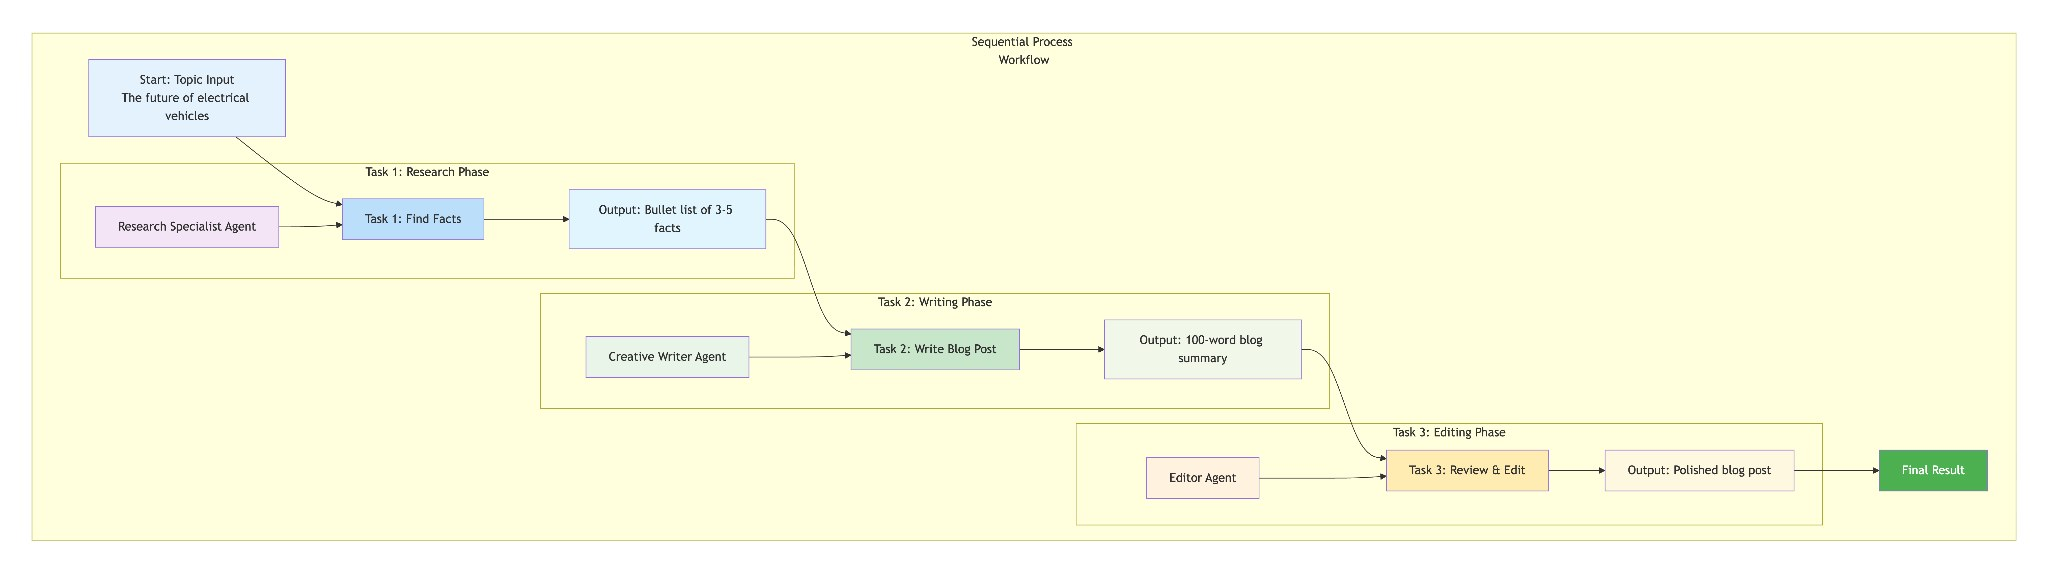

*From the session plan: research, then writing, then editing, each task feeding the next. We built the first two steps; adding the editor is your first exercise.*

**Try it:** run the crew again with a different topic, for example `inputs={"topic": "street food in Amritsar"}`. Same crew, new trip.

You've now used all four of CrewAI's building blocks:

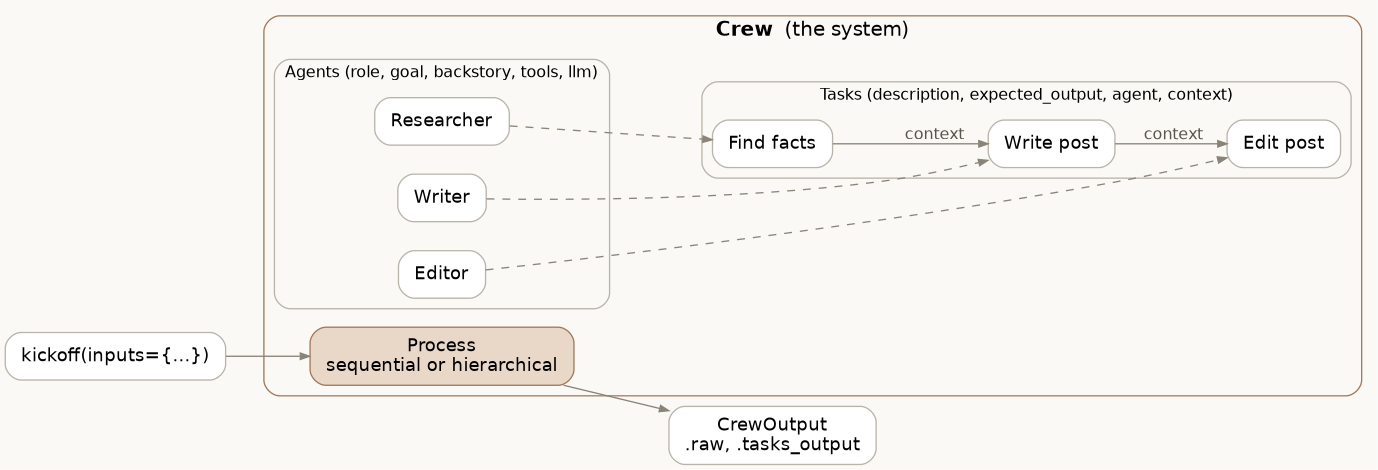

*A **Crew** holds **Agents** and **Tasks**; the **Process** decides how the tasks run.*

| Building block | What it is | Like... |
|---|---|---|
| **Agent** | A worker with a role, goal, backstory and tools | An employee |
| **Task** | A job: what to do, what good looks like, who does it | A ticket on a to-do board |
| **Crew** | The team: its agents and its tasks | A project team |
| **Process** | How the tasks run: in order, or under a manager | How the team is managed |

## Step 5: a manager who decides

In the pipeline, *we* decided who does what: each task named its agent. In a **hierarchical** process, a **manager** decides instead. This is Session 5's **manager/worker** pattern.

Two changes:

1. Use `process=Process.hierarchical`, and give the crew a model for the manager with `manager_llm=llm`. CrewAI creates the manager agent for you.
2. **Leave the task's `agent` empty**, so the manager can choose who does it.

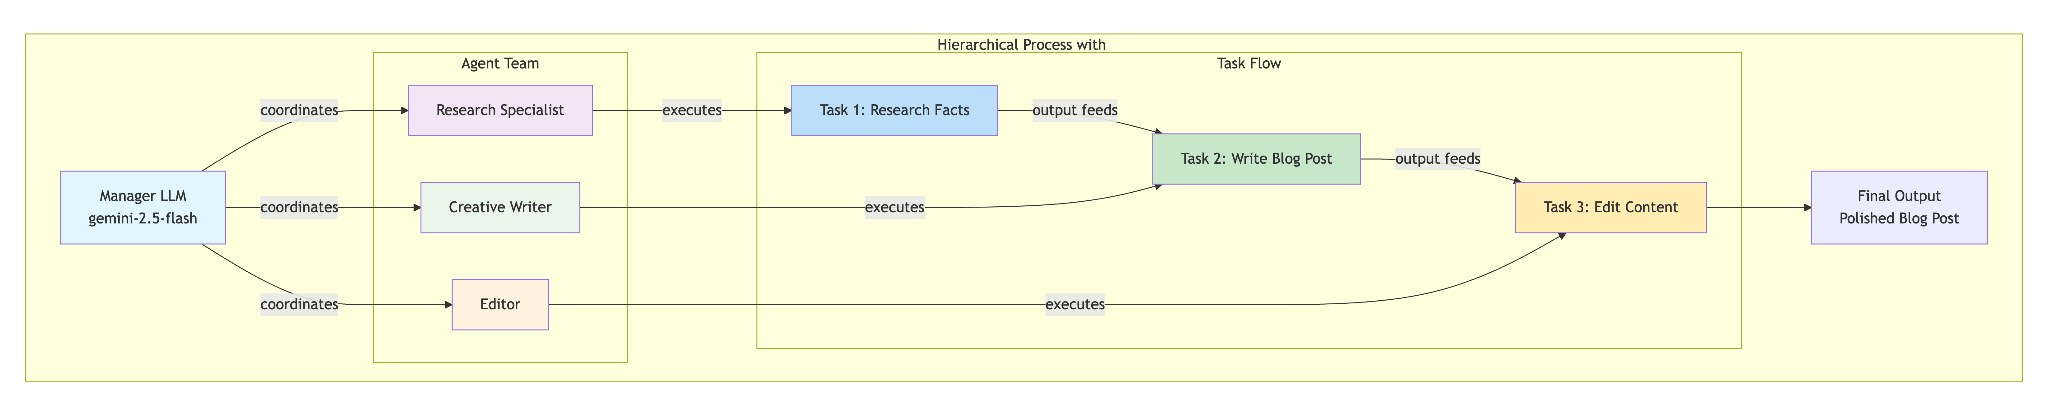

*From the session plan: a manager coordinates the specialists.*

We set `verbose=True` on the crew so you can watch the manager delegate.

In [ ]:
welcome_task = Task(
    description=("Write a short welcome note for a couple visiting {place} next week: "
                 "3 facts about the place from the travel guide, then one warm paragraph."),
    expected_output="A welcome note: 3 facts, then one paragraph. Under 120 words.",
    # no agent= here: the manager decides who does this
)

managed_crew = Crew(
    agents=[researcher, writer],
    tasks=[welcome_task],
    process=Process.hierarchical,
    manager_llm=llm,
    max_rpm=4,
    verbose=True,
)

result = await managed_crew.kickoff_async(inputs={"place": "Old Manali"})
print("\nFINAL NOTE:\n" + result.raw)

In the log, look for **`delegate_work_to_coworker`** (CrewAI may also write it as "Delegate work to coworker"): that's the manager handing part of the job to the researcher or the writer. Nobody told it the order; it decided.

Two things worth knowing about managers:

- **If you assign the task to an agent, the manager has no choice.** It can only pass that task to the agent you named, so you get a pipeline with an extra manager in the middle (and extra model calls). Leave tasks unassigned when you want the manager to choose.
- **A manager can't have tools.** Its only job is to delegate. If you build your own manager with `Agent(...)` and give it tools, CrewAI refuses to start with the error "Manager agent should not have tools".

## Step 6: agents asking each other

Sometimes one agent needs help from another in the middle of its own work. Give an agent **`allow_delegation=True`**, and CrewAI hands it two extra tools: one to *delegate work to a coworker* and one to *ask a coworker a question*.

DilSeTrips' copywriter writes homepage blurbs. It's good with words, but has no tools; the fact checker can read the travel guide. The copywriter is allowed to ask.

In [ ]:
fact_checker = Agent(
    role="Fact checker",
    goal="Answer questions about places accurately, using the travel guide.",
    backstory="You check every claim against the travel guide.",
    tools=[search_travel_guide],
    llm=llm,
)

copywriter = Agent(
    role="Copywriter",
    goal="Write short, specific homepage blurbs for DilSeTrips destinations.",
    backstory="You never state a fact you haven't checked. When unsure, you ask the fact checker.",
    llm=llm,
    allow_delegation=True,            # lets the copywriter ask its coworkers for help
)
print("Two agents ready.")

In [ ]:
blurb_task = Task(
    description="Write a two-sentence homepage blurb about Old Manali for couples. Mention two specific places, checked with the fact checker.",
    expected_output="A two-sentence blurb.",
    agent=copywriter,
)

helping_crew = Crew(agents=[copywriter, fact_checker], tasks=[blurb_task], max_rpm=4, verbose=True)

result = await helping_crew.kickoff_async()
print("\nBLURB:\n" + result.raw)

In the log, look for **`ask_question_to_coworker`** (or "Ask question to coworker"): the copywriter asking the fact checker, who then uses the travel guide. Two agents collaborating directly, with no manager in between.

If the copywriter didn't ask this time, that's a lesson too: `allow_delegation=True` makes asking *possible*, not *required*. The model decides, and a confident agent may skip the check.

## Session 5's patterns, in CrewAI

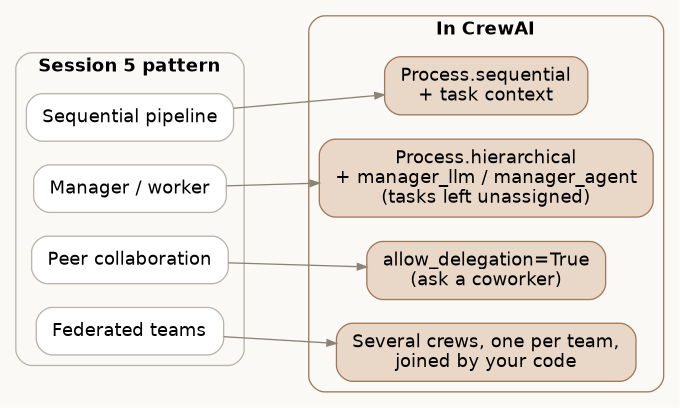

*Each design pattern from Session 5 has a natural CrewAI form.*

| Session 5 pattern | In CrewAI | Where you saw it |
|---|---|---|
| Pipeline | `Process.sequential` and `context=[...]` | Step 4 |
| Manager/worker | `Process.hierarchical`, tasks left unassigned | Step 5 |
| Peer collaboration | `allow_delegation=True` | Step 6 |
| Federated teams | One crew per team, results combined in your code | Exercise 5 |

## A word on memory

Inside one run, results already flow between tasks through `context`. For memory **across** runs, CrewAI has `memory=True` on a crew. Two things to know before you try it: it needs an embedding model (by default OpenAI's, so with only a Gemini key you must set `embedder=` to Gemini's), and it makes extra model calls to decide what to remember. On the free tier, try it last.

## What CrewAI did for us, and what it didn't

| | LangChain (Session 6A) | CrewAI (this notebook) |
|---|---|---|
| Passing results between agents | Your code | `context=[...]` |
| Deciding who does what | Your router and rules | A process setting, or a manager |
| Agents asking each other | Your peer tools | `allow_delegation=True` |
| Seeing every decision | Yes: you wrote every prompt | Partly: CrewAI writes the teamwork prompts |
| Control over cost | Exact | Less: managers and coworker questions add calls |

CrewAI removed most of the teamwork code. It didn't remove a single decision: you still chose the roles, wrote the goals and backstories (which are prompts), decided which tasks to assign, and picked the process.

## Exercises

1. **[Easy] Add the editor.** Add a third agent, an editor, and a third task that polishes the blog post. Which `context` does it need? Run it for a new topic.
2. **[Easy] Change a personality.** Give the writer a different backstory (a poet? a stand-up comic?) and compare the posts.
3. **[Medium] Assigned vs unassigned.** In Step 5, add `agent=writer` to the welcome task and run it again. What changed in the log? Was the manager worth its extra calls?
4. **[Medium] Is the coworker question worth it?** In Step 6, set `allow_delegation=False` on the copywriter. Does the blurb change? How would you know if the copywriter skipped a check it should have made?
5. **[Hard] Federated teams.** Build two small crews: a destination team (researcher and writer) and a packing team (an agent that suggests what to pack). Run both, then combine their results in plain Python. Ask both teams for exactly three lines starting with "- ", so combining is easy.

## Quick reference

| Idea | Code |
|---|---|
| Agent | `Agent(role="...", goal="...", backstory="...", tools=[...], llm=llm)` |
| Tool | `@tool("Name")` above a function with a docstring |
| Run one agent | `result = await agent.kickoff_async("message")`, then `result.raw` |
| Task | `Task(description="...", expected_output="...", agent=..., context=[...])` |
| Crew in order | `Crew(agents=[...], tasks=[...], process=Process.sequential, max_rpm=4)` |
| Crew with a manager | `process=Process.hierarchical, manager_llm=llm`, tasks without `agent=` |
| Fill placeholders | `await crew.kickoff_async(inputs={"topic": "..."})` |
| Each task's result | `for t in result.tasks_output: print(t.agent, t.raw)` |
| Agents asking each other | `allow_delegation=True` |
| Watch the thinking | `verbose=True` on an agent or a crew |
| Stay in the free tier | `max_rpm=4` |
| Notebook safety | `os.environ["CREWAI_TRACING_ENABLED"] = "false"` before anything runs |